In [6]:
import numpy as np
import pandas as pd


In [7]:
cd Desktop/practica

[WinError 3] The system cannot find the path specified: 'Desktop/practica'
C:\Users\FMI\Desktop\practica


C:\Users\FMI\anaconda3\envs\notebook\Lib\site-packages\IPython\core\magics\osm.py:393: UserWarning: This is now an optional IPython functionality, using bookmarks requires you to install the `pickleshare` library.
  bkms = self.shell.db.get('bookmarks', {})


In [8]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score
from catboost import CatBoostClassifier, Pool
# cd Desktop/practica
# Load the dataset
df = pd.read_csv("train.csv")

# Drop irrelevant columns if any
df.dropna(inplace=True)  # Or use imputation if needed

# Encode categorical columns (CatBoost handles this natively!)
target_col = 'Attack_type'
X = df.drop(target_col, axis=1)
y = df[target_col]

# Identify categorical features for CatBoost
cat_features = X.select_dtypes(include='object').columns.tolist()

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

# Create Pool for CatBoost
train_pool = Pool(X_train, y_train, cat_features=cat_features)
test_pool = Pool(X_test, y_test, cat_features=cat_features)

# Define and train the model
model = CatBoostClassifier(
    iterations=500,
    learning_rate=0.05,
    depth=6,
    loss_function='MultiClass',
    eval_metric='Accuracy',
    verbose=50
)

model.fit(train_pool, eval_set=test_pool)
model.save_model("catboost_model.cbm")
# Predictions and evaluation
y_pred = model.predict(X_test)
y_pred = y_pred.flatten()  # If needed to match shape

print("\nAccuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))


0:	learn: 0.9714167	test: 0.9709167	best: 0.9709167 (0)	total: 2.64s	remaining: 21m 58s
50:	learn: 0.9942500	test: 0.9939167	best: 0.9940833 (45)	total: 2m 31s	remaining: 22m 12s
100:	learn: 0.9975104	test: 0.9972500	best: 0.9972917 (99)	total: 5m 2s	remaining: 19m 55s
150:	learn: 0.9980625	test: 0.9975833	best: 0.9976250 (137)	total: 7m 49s	remaining: 18m 4s
200:	learn: 0.9984167	test: 0.9980833	best: 0.9981250 (178)	total: 10m 38s	remaining: 15m 50s
250:	learn: 0.9985104	test: 0.9980833	best: 0.9981250 (178)	total: 13m 25s	remaining: 13m 18s
300:	learn: 0.9986250	test: 0.9982500	best: 0.9983333 (291)	total: 16m 20s	remaining: 10m 48s
350:	learn: 0.9989583	test: 0.9986667	best: 0.9986667 (331)	total: 19m 9s	remaining: 8m 8s
400:	learn: 0.9990104	test: 0.9987500	best: 0.9987917 (365)	total: 21m 53s	remaining: 5m 24s
450:	learn: 0.9990417	test: 0.9987917	best: 0.9987917 (365)	total: 24m 43s	remaining: 2m 41s
499:	learn: 0.9991250	test: 0.9988333	best: 0.9988750 (486)	total: 27m 29s	rema

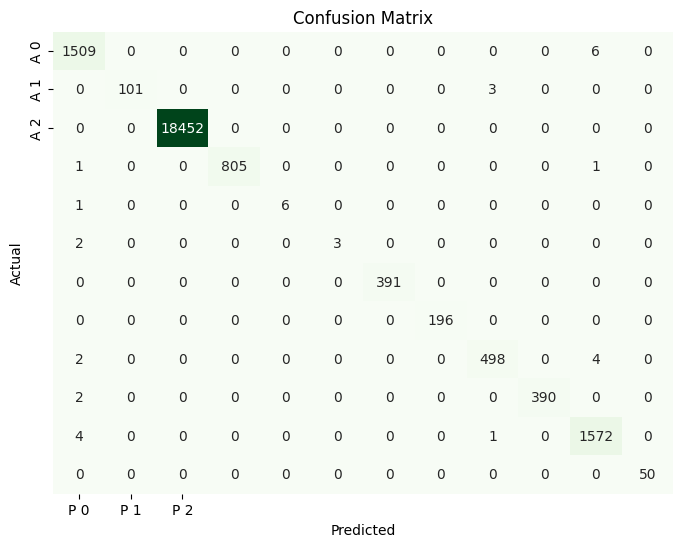

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Greens', cbar=False,
            xticklabels=['P 0', 'P 1', 'P 2'],
            yticklabels=['A 0', 'A 1', 'A 2'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [16]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

                            precision    recall  f1-score   support

            ARP_poisioning       0.99      1.00      0.99      1515
            DDOS_Slowloris       1.00      0.97      0.99       104
             DOS_SYN_Hping       1.00      1.00      1.00     18452
              MQTT_Publish       1.00      1.00      1.00       807
Metasploit_Brute_Force_SSH       1.00      0.86      0.92         7
             NMAP_FIN_SCAN       1.00      0.60      0.75         5
         NMAP_OS_DETECTION       1.00      1.00      1.00       391
             NMAP_TCP_scan       1.00      1.00      1.00       196
             NMAP_UDP_SCAN       0.99      0.99      0.99       504
       NMAP_XMAS_TREE_SCAN       1.00      0.99      1.00       392
               Thing_Speak       0.99      1.00      0.99      1577
                Wipro_bulb       1.00      1.00      1.00        50

                  accuracy                           1.00     24000
                 macro avg       1.00      0.9

In [17]:
from sklearn.metrics import matthews_corrcoef

matthews_corrcoef(y_test, y_pred)

np.float64(0.9971762316784006)